# Paper Output Examples: Plate Detection, Deblurring, and OCR

This notebook creates 2-3 paper-ready qualitative pipeline examples:

1. source vehicle image with YOLO plate detection box
2. YOLO-cropped plate image
3. synthesized blurry/degraded plate crop
4. DeblurGAN-enhanced plate crop
5. OCR token prediction on the enhanced crop

It uses the already trained checkpoints and does not retrain any model.

In [ ]:
from pathlib import Path
import os
import math
import random
import unicodedata

import cv2
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PROJECT_ROOT = Path.cwd()
SOURCE_IMAGE_ROOT = PROJECT_ROOT / "clean dataset"
OUTPUT_ROOT = PROJECT_ROOT / "runs" / "paper_pipeline_examples_final"

YOLO_PLATE_WEIGHTS = PROJECT_ROOT / "runs" / "bangla_plate_yolov8" / "plate_motion_blur_distortion_exp" / "weights" / "best.pt"
DEBLURGAN_CHECKPOINT = PROJECT_ROOT / "runs" / "deblurgan_clean_dataset_irv2_fpn_psnr_v2" / "checkpoints" / "best_generator.pt"
YOLO_TOKEN_WEIGHTS = PROJECT_ROOT / "runs" / "ocr_text_recognition_psnr_v2" / "yolo_token_ocr" / "yolov8_token_detector" / "weights" / "best.pt"

# Change these names if you want different paper examples.
SAMPLE_IMAGE_NAMES = [
    "Vehicle1285.jpg",
    "Vehicle1247.jpg",
    "Vehicle1093.jpg",
]

PLATE_HEIGHT = 96
PLATE_WIDTH = 256
YOLO_IMAGE_SIZE = 640
YOLO_CONFIDENCE = 0.25
OCR_IMAGE_SIZE = 320
OCR_CONFIDENCE = 0.20
OCR_IOU = 0.45
BOTTOM_DIGIT_COUNT = 6
CROP_PAD_RATIO = 0.04

TORCH_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"

for folder in [
    OUTPUT_ROOT,
    OUTPUT_ROOT / "source_boxed",
    OUTPUT_ROOT / "yolo_crops",
    OUTPUT_ROOT / "synthetic_blurry",
    OUTPUT_ROOT / "deblurred",
    OUTPUT_ROOT / "ocr_overlay",
    OUTPUT_ROOT / "ultralytics_config",
]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ.setdefault("YOLO_CONFIG_DIR", str(OUTPUT_ROOT / "ultralytics_config"))

def require_path(path, label):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing {label}: {path}")

require_path(SOURCE_IMAGE_ROOT, "source vehicle image folder")
require_path(YOLO_PLATE_WEIGHTS, "YOLOv8 plate detector weights")
require_path(DEBLURGAN_CHECKPOINT, "DeblurGAN generator checkpoint")
require_path(YOLO_TOKEN_WEIGHTS, "YOLOv8 token OCR weights")
for image_name in SAMPLE_IMAGE_NAMES:
    require_path(SOURCE_IMAGE_ROOT / image_name, f"sample image {image_name}")

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for candidate in ["Nirmala UI", "Vrinda", "Kalpurush", "SolaimanLipi", "Arial Unicode MS", "DejaVu Sans"]:
    if candidate in available_fonts:
        plt.rcParams["font.family"] = candidate
        print("Matplotlib font:", candidate)
        break

print("Project root:", PROJECT_ROOT)
print("Output root:", OUTPUT_ROOT)
print("Torch device:", TORCH_DEVICE)

## DeblurGAN Generator

This is the same notebook-local Inception-ResNet-V2-style FPN generator architecture used by the saved DeblurGAN checkpoint.

In [ ]:
def group_norm(channels):
    groups = 8 if channels % 8 == 0 else 1
    return nn.GroupNorm(groups, channels)


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, bias=False),
            group_norm(out_channels),
            nn.SiLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class InceptionResNetA(nn.Module):
    def __init__(self, channels, scale=0.17):
        super().__init__()
        self.scale = scale
        self.branch_1 = ConvBlock(channels, 32, kernel_size=1)
        self.branch_2 = nn.Sequential(ConvBlock(channels, 32, kernel_size=1), ConvBlock(32, 32, kernel_size=3))
        self.branch_3 = nn.Sequential(ConvBlock(channels, 32, kernel_size=1), ConvBlock(32, 48, kernel_size=3), ConvBlock(48, 64, kernel_size=3))
        self.projection = nn.Conv2d(128, channels, kernel_size=1)
        self.activation = nn.SiLU(inplace=True)

    def forward(self, x):
        residual = torch.cat([self.branch_1(x), self.branch_2(x), self.branch_3(x)], dim=1)
        return self.activation(x + self.scale * self.projection(residual))


class InceptionResNetB(nn.Module):
    def __init__(self, channels, scale=0.10):
        super().__init__()
        self.scale = scale
        self.branch_1 = ConvBlock(channels, 96, kernel_size=1)
        self.branch_2 = nn.Sequential(
            ConvBlock(channels, 64, kernel_size=1),
            nn.Conv2d(64, 80, kernel_size=(1, 7), padding=(0, 3), bias=False),
            group_norm(80),
            nn.SiLU(inplace=True),
            nn.Conv2d(80, 96, kernel_size=(7, 1), padding=(3, 0), bias=False),
            group_norm(96),
            nn.SiLU(inplace=True),
        )
        self.projection = nn.Conv2d(192, channels, kernel_size=1)
        self.activation = nn.SiLU(inplace=True)

    def forward(self, x):
        residual = torch.cat([self.branch_1(x), self.branch_2(x)], dim=1)
        return self.activation(x + self.scale * self.projection(residual))


class InceptionResNetC(nn.Module):
    def __init__(self, channels, scale=0.20):
        super().__init__()
        self.scale = scale
        self.branch_1 = ConvBlock(channels, 96, kernel_size=1)
        self.branch_2 = nn.Sequential(
            ConvBlock(channels, 64, kernel_size=1),
            nn.Conv2d(64, 96, kernel_size=(1, 3), padding=(0, 1), bias=False),
            group_norm(96),
            nn.SiLU(inplace=True),
            nn.Conv2d(96, 96, kernel_size=(3, 1), padding=(1, 0), bias=False),
            group_norm(96),
            nn.SiLU(inplace=True),
        )
        self.projection = nn.Conv2d(192, channels, kernel_size=1)
        self.activation = nn.SiLU(inplace=True)

    def forward(self, x):
        residual = torch.cat([self.branch_1(x), self.branch_2(x)], dim=1)
        return self.activation(x + self.scale * self.projection(residual))


class ReductionA(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.branch_1 = ConvBlock(in_channels, 192, kernel_size=3, stride=2)
        self.branch_2 = nn.Sequential(ConvBlock(in_channels, 128, kernel_size=1), ConvBlock(128, 160, kernel_size=3), ConvBlock(160, 192, kernel_size=3, stride=2))
        self.branch_3 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.projection = ConvBlock(in_channels + 384, out_channels, kernel_size=1)

    def forward(self, x):
        merged = torch.cat([self.branch_1(x), self.branch_2(x), self.branch_3(x)], dim=1)
        return self.projection(merged)


class ReductionB(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.branch_1 = nn.Sequential(ConvBlock(in_channels, 192, kernel_size=1), ConvBlock(192, 256, kernel_size=3, stride=2))
        self.branch_2 = nn.Sequential(ConvBlock(in_channels, 192, kernel_size=1), ConvBlock(192, 224, kernel_size=3), ConvBlock(224, 256, kernel_size=3, stride=2))
        self.branch_3 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.projection = ConvBlock(in_channels + 512, out_channels, kernel_size=1)

    def forward(self, x):
        merged = torch.cat([self.branch_1(x), self.branch_2(x), self.branch_3(x)], dim=1)
        return self.projection(merged)


class LocalInceptionResNetV2Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.feature_channels = [32, 64, 192, 384, 768]
        self.stem_1 = ConvBlock(3, 32, kernel_size=3, stride=2)
        self.stem_2 = ConvBlock(32, 64, kernel_size=3, stride=2)
        self.stem_3 = nn.Sequential(ConvBlock(64, 128, kernel_size=3, stride=2), ConvBlock(128, 192, kernel_size=3))
        self.block_a = nn.Sequential(InceptionResNetA(192), InceptionResNetA(192), InceptionResNetA(192))
        self.reduction_a = ReductionA(192, 384)
        self.block_b = nn.Sequential(InceptionResNetB(384), InceptionResNetB(384), InceptionResNetB(384))
        self.reduction_b = ReductionB(384, 768)
        self.block_c = nn.Sequential(InceptionResNetC(768), InceptionResNetC(768))

    def forward(self, x):
        f0 = self.stem_1(x)
        f1 = self.stem_2(f0)
        f2 = self.stem_3(f1)
        f2 = self.block_a(f2)
        f3 = self.reduction_a(f2)
        f3 = self.block_b(f3)
        f4 = self.reduction_b(f3)
        f4 = self.block_c(f4)
        return [f0, f1, f2, f3, f4]


class FPNInceptionResNetV2Generator(nn.Module):
    def __init__(self, fpn_channels=128):
        super().__init__()
        self.backbone = LocalInceptionResNetV2Backbone()
        channels = self.backbone.feature_channels
        self.lateral = nn.ModuleList([nn.Conv2d(channel, fpn_channels, kernel_size=1) for channel in channels])
        self.smooth = nn.ModuleList([ConvBlock(fpn_channels, fpn_channels) for _ in channels])
        self.decoder = nn.Sequential(
            ConvBlock(fpn_channels * len(channels), fpn_channels),
            ConvBlock(fpn_channels, fpn_channels // 2),
            ConvBlock(fpn_channels // 2, fpn_channels // 4),
            nn.Conv2d(fpn_channels // 4, 3, kernel_size=3, padding=1),
        )

    def forward(self, x):
        input_height, input_width = x.shape[-2:]
        features = self.backbone(x)
        pyramid = [None] * len(features)
        top = self.lateral[-1](features[-1])
        pyramid[-1] = self.smooth[-1](top)

        for index in range(len(features) - 2, -1, -1):
            top = F.interpolate(top, size=features[index].shape[-2:], mode="bilinear", align_corners=False)
            top = top + self.lateral[index](features[index])
            pyramid[index] = self.smooth[index](top)

        fused = torch.cat(
            [F.interpolate(level, size=(input_height, input_width), mode="bilinear", align_corners=False) for level in pyramid],
            dim=1,
        )
        residual = torch.tanh(self.decoder(fused)) * 0.5
        return torch.clamp(x + residual, 0.0, 1.0)


def load_trained_generator(checkpoint_path=DEBLURGAN_CHECKPOINT):
    model = FPNInceptionResNetV2Generator().to(TORCH_DEVICE)
    try:
        checkpoint = torch.load(checkpoint_path, map_location=TORCH_DEVICE, weights_only=False)
    except TypeError:
        checkpoint = torch.load(checkpoint_path, map_location=TORCH_DEVICE)
    state_dict = checkpoint["generator"] if isinstance(checkpoint, dict) and "generator" in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model


@torch.no_grad()
def deblur_crop_array(generator_model, crop_bgr):
    resized = cv2.resize(crop_bgr, (PLATE_WIDTH, PLATE_HEIGHT), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(rgb).permute(2, 0, 1).float().unsqueeze(0) / 255.0
    tensor = tensor.to(TORCH_DEVICE)
    restored = generator_model(tensor)[0]
    restored_rgb = (restored.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    return cv2.cvtColor(restored_rgb, cv2.COLOR_RGB2BGR)


generator_model = load_trained_generator()
print("Loaded DeblurGAN generator:", DEBLURGAN_CHECKPOINT)

## Detection, Degradation, OCR, and Figure Helpers

In [ ]:
from ultralytics import YOLO

plate_model = YOLO(str(YOLO_PLATE_WEIGHTS))
ocr_model = YOLO(str(YOLO_TOKEN_WEIGHTS))
print("Loaded YOLO plate detector:", YOLO_PLATE_WEIGHTS)
print("Loaded YOLO token OCR:", YOLO_TOKEN_WEIGHTS)

BANGLA_DIGITS = {
    "0": "\u09e6", "1": "\u09e7", "2": "\u09e8", "3": "\u09e9", "4": "\u09ea",
    "5": "\u09eb", "6": "\u09ec", "7": "\u09ed", "8": "\u09ee", "9": "\u09ef",
}
BANGLA_DIGIT_VALUES = set(BANGLA_DIGITS.values())
TARGET_TOKEN_ALIASES = {
    "dhaka": "\u09a2\u09be\u0995\u09be",
    "chattro": "\u099a\u099f\u09cd\u099f",
    "sylhet": "\u09b8\u09bf\u09b2\u09c7\u099f",
    "metro": "\u09ae\u09c7\u099f\u09cd\u09b0\u09cb",
    "ka": "\u0995", "kha": "\u0996", "ga": "\u0997", "gha": "\u0998",
    "cha": "\u099a", "chha": "\u099b", "ja": "\u099c", "jha": "\u099d",
    "ta": "\u099f", "tha": "\u09a0", "ba": "\u09ac", "bha": "\u09ad",
    "m": "\u09ae", "na": "\u09a8", "sa": "\u09b8",
}

YOLO_TOKEN_CLASS_NAMES = [
    "dhaka", "chattro", "sylhet", "metro",
    "ka", "kha", "ga", "gha", "cha", "chha", "ja", "jha", "ta", "tha", "ba", "bha", "m", "na", "sa",
    "0", "1", "2", "3", "4", "5", "6", "7", "8", "9",
]
YOLO_TOKEN_TO_BANGLA = {
    "dhaka": TARGET_TOKEN_ALIASES["dhaka"],
    "chattro": TARGET_TOKEN_ALIASES["chattro"],
    "sylhet": TARGET_TOKEN_ALIASES["sylhet"],
    "metro": TARGET_TOKEN_ALIASES["metro"],
    "ka": TARGET_TOKEN_ALIASES["ka"], "kha": TARGET_TOKEN_ALIASES["kha"],
    "ga": TARGET_TOKEN_ALIASES["ga"], "gha": TARGET_TOKEN_ALIASES["gha"],
    "cha": TARGET_TOKEN_ALIASES["cha"], "chha": TARGET_TOKEN_ALIASES["chha"],
    "ja": TARGET_TOKEN_ALIASES["ja"], "jha": TARGET_TOKEN_ALIASES["jha"],
    "ta": TARGET_TOKEN_ALIASES["ta"], "tha": TARGET_TOKEN_ALIASES["tha"],
    "ba": TARGET_TOKEN_ALIASES["ba"], "bha": TARGET_TOKEN_ALIASES["bha"],
    "m": TARGET_TOKEN_ALIASES["m"], "na": TARGET_TOKEN_ALIASES["na"], "sa": TARGET_TOKEN_ALIASES["sa"],
    **{str(index): BANGLA_DIGITS[str(index)] for index in range(10)},
}
YOLO_INDEX_TO_BANGLA = {index: YOLO_TOKEN_TO_BANGLA[name] for index, name in enumerate(YOLO_TOKEN_CLASS_NAMES)}
CITY_TOKENS = [TARGET_TOKEN_ALIASES["dhaka"], TARGET_TOKEN_ALIASES["chattro"], TARGET_TOKEN_ALIASES["sylhet"]]
METRO_TOKEN = TARGET_TOKEN_ALIASES["metro"]
SERIES_TOKEN_KEYS = ["ka", "kha", "ga", "gha", "cha", "chha", "ja", "jha", "ta", "tha", "ba", "bha", "m", "na", "sa"]
SERIES_TOKENS = {TARGET_TOKEN_ALIASES[key] for key in SERIES_TOKEN_KEYS}
ASCII_TO_BANGLA_DIGIT = str.maketrans(BANGLA_DIGITS)


def normalize_text(text):
    if text is None or (isinstance(text, float) and math.isnan(text)):
        text = ""
    text = unicodedata.normalize("NFC", str(text)).translate(ASCII_TO_BANGLA_DIGIT)
    kept = []
    for char in text:
        if char.isspace():
            kept.append(" ")
        elif "\u0980" <= char <= "\u09ff":
            kept.append(char)
        elif char.isalnum():
            kept.append(char.lower())
    return " ".join("".join(kept).split())


def pad_and_clip_xyxy(box, width, height, pad_ratio=CROP_PAD_RATIO):
    x1, y1, x2, y2 = [float(value) for value in box]
    box_width = max(1.0, x2 - x1)
    box_height = max(1.0, y2 - y1)
    pad_x = box_width * pad_ratio
    pad_y = box_height * pad_ratio
    x1 = max(0, int(round(x1 - pad_x)))
    y1 = max(0, int(round(y1 - pad_y)))
    x2 = min(width, int(round(x2 + pad_x)))
    y2 = min(height, int(round(y2 + pad_y)))
    if x2 <= x1 or y2 <= y1:
        return None
    return x1, y1, x2, y2


def yolo_label_box_for_image(image_path):
    label_path = image_path.with_suffix(".txt")
    if not label_path.exists():
        return None
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        return None
    height, width = image.shape[:2]
    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.strip().split()
        if len(parts) < 5:
            continue
        _, x_center, y_center, box_width, box_height = map(float, parts[:5])
        x1 = (x_center - box_width / 2) * width
        y1 = (y_center - box_height / 2) * height
        x2 = (x_center + box_width / 2) * width
        y2 = (y_center + box_height / 2) * height
        return [x1, y1, x2, y2], 1.0, "label_fallback"
    return None


def detect_plate_box(image_path):
    results = plate_model.predict(
        source=str(image_path),
        imgsz=YOLO_IMAGE_SIZE,
        conf=YOLO_CONFIDENCE,
        device=YOLO_DEVICE,
        verbose=False,
    )
    result = results[0] if results else None
    if result is not None and result.boxes is not None and len(result.boxes) > 0:
        boxes = result.boxes.xyxy.detach().cpu().numpy()
        confidences = result.boxes.conf.detach().cpu().numpy()
        best_index = int(np.argmax(confidences))
        return [float(value) for value in boxes[best_index]], float(confidences[best_index]), "yolov8"
    fallback = yolo_label_box_for_image(Path(image_path))
    if fallback is not None:
        return fallback
    raise RuntimeError(f"No plate detection found for {image_path}")


def crop_plate(image_bgr, box):
    height, width = image_bgr.shape[:2]
    clipped = pad_and_clip_xyxy(box, width, height)
    if clipped is None:
        raise RuntimeError("Invalid crop box")
    x1, y1, x2, y2 = clipped
    crop = image_bgr[y1:y2, x1:x2]
    return cv2.resize(crop, (PLATE_WIDTH, PLATE_HEIGHT), interpolation=cv2.INTER_AREA), clipped


def make_motion_kernel(size=11, angle=12.0):
    kernel = np.zeros((size, size), dtype=np.float32)
    center = size // 2
    cv2.line(kernel, (0, center), (size - 1, center), 1.0, 1)
    matrix = cv2.getRotationMatrix2D((center, center), angle, 1.0)
    kernel = cv2.warpAffine(kernel, matrix, (size, size))
    kernel_sum = kernel.sum()
    if kernel_sum <= 0:
        kernel[center, center] = 1.0
        kernel_sum = 1.0
    return kernel / kernel_sum


def synthesize_blurry_crop(crop_bgr, index=0):
    angle = [-14.0, 9.0, 16.0, -8.0][index % 4]
    kernel_size = [9, 11, 7, 9][index % 4]
    degraded = cv2.filter2D(crop_bgr, -1, make_motion_kernel(kernel_size, angle))
    degraded = cv2.GaussianBlur(degraded, (3, 3), 0)
    degraded = cv2.convertScaleAbs(degraded, alpha=0.94, beta=-3)
    rng = np.random.default_rng(SEED + index)
    noise = rng.normal(0.0, 3.5, degraded.shape).astype(np.float32)
    degraded = np.clip(degraded.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    ok, encoded = cv2.imencode(".jpg", degraded, [cv2.IMWRITE_JPEG_QUALITY, 82])
    if ok:
        degraded = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return degraded


def best_detection(detections, predicate):
    candidates = [item for item in detections if predicate(item)]
    if not candidates:
        return None
    return max(candidates, key=lambda item: item["confidence"])


def dedupe_digit_detections(digits, min_distance=8.0):
    digits = sorted(digits, key=lambda item: item["confidence"], reverse=True)
    kept = []
    for digit in digits:
        if all(abs(digit["x_center"] - other["x_center"]) >= min_distance for other in kept):
            kept.append(digit)
    return sorted(kept, key=lambda item: item["x_center"])


def enforce_yolo_digit_count(text):
    digits = "".join(char for char in normalize_text(text) if char in BANGLA_DIGIT_VALUES)
    if len(digits) == BOTTOM_DIGIT_COUNT:
        return digits
    if len(digits) > BOTTOM_DIGIT_COUNT:
        return digits[:BOTTOM_DIGIT_COUNT]
    return digits


def decode_yolo_token_detections(detections):
    city = best_detection(detections, lambda item: item["is_city"])
    metro = best_detection(detections, lambda item: item["is_metro"])
    series = best_detection(detections, lambda item: item["is_series"])
    top_parts = []
    if city is not None:
        top_parts.append(city["token"])
    if metro is not None:
        top_parts.append(METRO_TOKEN)
    if series is not None:
        top_parts.append(series["token"])

    digit_detections = dedupe_digit_detections([item for item in detections if item["is_digit"]])
    if len(digit_detections) > BOTTOM_DIGIT_COUNT:
        digit_detections = sorted(digit_detections, key=lambda item: item["confidence"], reverse=True)[:BOTTOM_DIGIT_COUNT]
        digit_detections = sorted(digit_detections, key=lambda item: item["x_center"])
    bottom_text = "".join(item["token"] for item in digit_detections)
    if len(bottom_text) != BOTTOM_DIGIT_COUNT:
        bottom_text = enforce_yolo_digit_count(bottom_text)
    return normalize_text(" ".join(part for part in [" ".join(top_parts).strip(), bottom_text] if part).strip())


def detections_from_ocr_result(result):
    detections = []
    if result is None or result.boxes is None:
        return detections
    xyxy = result.boxes.xyxy.detach().cpu().numpy()
    classes = result.boxes.cls.detach().cpu().numpy().astype(int)
    confidences = result.boxes.conf.detach().cpu().numpy()
    for box, class_index, confidence in zip(xyxy, classes, confidences):
        if int(class_index) not in YOLO_INDEX_TO_BANGLA:
            continue
        x1, y1, x2, y2 = map(float, box)
        token = YOLO_INDEX_TO_BANGLA[int(class_index)]
        detections.append({
            "token": token,
            "confidence": float(confidence),
            "x1": x1, "y1": y1, "x2": x2, "y2": y2,
            "x_center": (x1 + x2) / 2,
            "y_center": (y1 + y2) / 2,
            "is_digit": token in BANGLA_DIGIT_VALUES,
            "is_city": token in CITY_TOKENS,
            "is_series": token in SERIES_TOKENS,
            "is_metro": token == METRO_TOKEN,
        })
    return detections


def run_ocr_on_crop(crop_path):
    results = ocr_model.predict(
        source=str(crop_path),
        imgsz=OCR_IMAGE_SIZE,
        conf=OCR_CONFIDENCE,
        iou=OCR_IOU,
        device=YOLO_DEVICE,
        verbose=False,
    )
    result = results[0] if results else None
    detections = detections_from_ocr_result(result)
    prediction = decode_yolo_token_detections(detections)
    detected_tokens = " ".join(item["token"] for item in sorted(detections, key=lambda value: (value["y_center"], value["x_center"])))
    return prediction, detected_tokens, detections


def draw_source_box(image_bgr, box, confidence, source_kind):
    boxed = image_bgr.copy()
    x1, y1, x2, y2 = [int(round(value)) for value in box]
    cv2.rectangle(boxed, (x1, y1), (x2, y2), (20, 95, 255), 3)
    label = f"plate {confidence:.2f}" if source_kind == "yolov8" else "plate label"
    cv2.putText(boxed, label, (x1, max(24, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (20, 95, 255), 2, cv2.LINE_AA)
    return boxed


def draw_ocr_boxes(crop_bgr, detections):
    boxed = crop_bgr.copy()
    for item in detections:
        x1, y1, x2, y2 = [int(round(item[key])) for key in ["x1", "y1", "x2", "y2"]]
        color = (35, 150, 55) if item["is_digit"] else (230, 120, 30)
        cv2.rectangle(boxed, (x1, y1), (x2, y2), color, 1)
    return boxed


def bgr_to_rgb(image_bgr):
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def write_image(path, image_bgr):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), image_bgr)
    return path


def process_one_example(image_name, index):
    image_path = SOURCE_IMAGE_ROOT / image_name
    image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise FileNotFoundError(f"Could not read {image_path}")

    box, confidence, box_source = detect_plate_box(image_path)
    yolo_crop, clipped_box = crop_plate(image_bgr, box)
    blurry_crop = synthesize_blurry_crop(yolo_crop, index=index)
    deblurred_crop = deblur_crop_array(generator_model, blurry_crop)

    stem = Path(image_name).stem
    source_boxed = draw_source_box(image_bgr, clipped_box, confidence, box_source)
    source_boxed_path = write_image(OUTPUT_ROOT / "source_boxed" / f"{stem}_source_boxed.png", source_boxed)
    yolo_crop_path = write_image(OUTPUT_ROOT / "yolo_crops" / f"{stem}_yolo_crop.png", yolo_crop)
    blurry_path = write_image(OUTPUT_ROOT / "synthetic_blurry" / f"{stem}_synthetic_blurry.png", blurry_crop)
    deblurred_path = write_image(OUTPUT_ROOT / "deblurred" / f"{stem}_deblurred.png", deblurred_crop)

    prediction, detected_tokens, detections = run_ocr_on_crop(deblurred_path)
    ocr_overlay = draw_ocr_boxes(deblurred_crop, detections)
    ocr_overlay_path = write_image(OUTPUT_ROOT / "ocr_overlay" / f"{stem}_ocr_overlay.png", ocr_overlay)

    return {
        "image_name": image_name,
        "box_source": box_source,
        "plate_confidence": confidence,
        "ocr_prediction": prediction,
        "detected_tokens": detected_tokens,
        "detection_count": len(detections),
        "source_boxed_path": source_boxed_path.as_posix(),
        "yolo_crop_path": yolo_crop_path.as_posix(),
        "synthetic_blurry_path": blurry_path.as_posix(),
        "deblurred_path": deblurred_path.as_posix(),
        "ocr_overlay_path": ocr_overlay_path.as_posix(),
    }


def plot_pipeline_grid(records):
    columns = [
        ("source_boxed_path", "Full/source image\nYOLO plate detection"),
        ("yolo_crop_path", "YOLO-cropped\nplate"),
        ("synthetic_blurry_path", "Synthesized\nblurry crop"),
        ("deblurred_path", "DeblurGAN\nenhanced crop"),
        ("ocr_overlay_path", "OCR token\nprediction"),
    ]
    row_count = len(records)
    figure, axes = plt.subplots(row_count, len(columns), figsize=(17.5, 3.2 * row_count), facecolor="white")
    if row_count == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_index, record in enumerate(records):
        for column_index, (path_key, title) in enumerate(columns):
            axis = axes[row_index, column_index]
            image = cv2.imread(record[path_key], cv2.IMREAD_COLOR)
            axis.imshow(bgr_to_rgb(image))
            axis.axis("off")
            if row_index == 0:
                axis.set_title(title, fontsize=12, weight="bold")
            if column_index == 0:
                axis.text(0.02, 0.96, Path(record["image_name"]).stem, transform=axis.transAxes, va="top", ha="left", fontsize=10, color="white", bbox={"facecolor": "black", "alpha": 0.55, "pad": 3})
            if column_index == 4:
                prediction = record["ocr_prediction"] or "No OCR text"
                axis.text(0.5, -0.12, f"Prediction: {prediction}", transform=axis.transAxes, va="top", ha="center", fontsize=11)

    figure.tight_layout(h_pad=1.4, w_pad=0.55)
    png_path = OUTPUT_ROOT / "paper_pipeline_examples_grid.png"
    pdf_path = OUTPUT_ROOT / "paper_pipeline_examples_grid.pdf"
    figure.savefig(png_path, dpi=300, bbox_inches="tight")
    figure.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    print("Saved grid PNG:", png_path)
    print("Saved grid PDF:", pdf_path)
    return png_path, pdf_path

## Generate Paper Examples

Run this cell to create the composite figure and the per-stage image files.

In [ ]:
records = []
for index, image_name in enumerate(SAMPLE_IMAGE_NAMES):
    print(f"Processing {index + 1}/{len(SAMPLE_IMAGE_NAMES)}: {image_name}")
    records.append(process_one_example(image_name, index))

records_frame = pd.DataFrame(records)
records_path = OUTPUT_ROOT / "paper_pipeline_predictions.csv"
records_frame.to_csv(records_path, index=False, encoding="utf-8-sig")
plot_pipeline_grid(records)

print("Saved records CSV:", records_path)
display(records_frame[["image_name", "box_source", "plate_confidence", "ocr_prediction", "detected_tokens", "detection_count"]])

## DeblurGAN-v2 Paired Training Sample

This cell displays one existing sharp plate crop with three existing blurry variants from the DeblurGAN-v2 paired training dataset.

In [ ]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(".").resolve()
PAIR_ROOT = PROJECT_ROOT / "deblurgan_data" / "clean_dataset_paired_plate_crops_psnr_v2" / "test"
FIGURE_OUTPUT_ROOT = Path(globals().get("OUTPUT_ROOT", PROJECT_ROOT / "runs" / "paper_pipeline_examples_final"))
FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# These are existing random DeblurGAN-v2 blur variants, visually ordered here as low/medium/high.
training_sample_images = [
    ("Sharp plate", PAIR_ROOT / "sharp" / "Vehicle1043_plate_0_v0.png"),
    ("Low blur", PAIR_ROOT / "blurry" / "Vehicle1043_plate_0_v1.png"),
    ("Medium blur", PAIR_ROOT / "blurry" / "Vehicle1043_plate_0_v2.png"),
    ("High blur", PAIR_ROOT / "blurry" / "Vehicle1043_plate_0_v0.png"),
]

missing_paths = [path for _, path in training_sample_images if not path.exists()]
if missing_paths:
    raise FileNotFoundError("Missing DeblurGAN-v2 sample image(s):\n" + "\n".join(str(path) for path in missing_paths))

figure, axes = plt.subplots(1, len(training_sample_images), figsize=(12, 3.2))
for axis, (title, image_path) in zip(axes, training_sample_images):
    image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise RuntimeError(f"Could not read image: {image_path}")
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    axis.imshow(image_rgb)
    axis.set_title(title, fontsize=13, weight="bold")
    axis.axis("off")

figure.suptitle("Example of Paired DeblurGAN-v2 Training Samples", fontsize=15, weight="bold")
figure.tight_layout(rect=[0, 0, 1, 0.90], w_pad=0.6)

png_path = FIGURE_OUTPUT_ROOT / "deblurgan_v2_paired_training_blur_levels.png"
pdf_path = FIGURE_OUTPUT_ROOT / "deblurgan_v2_paired_training_blur_levels.pdf"
figure.savefig(png_path, dpi=300, bbox_inches="tight")
figure.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)

## Blur-Level and DeblurGAN Metric Graph

This cell computes average PSNR, SSIM, and MAE for low-, medium-, and high-blur variants across the DeblurGAN test split. For each plate, the three blurry variants are ranked by PSNR against the sharp target. The DeblurGAN row uses the overall full-test-set DeblurGAN average from the saved evaluation summary.

In [ ]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(".").resolve()
PAIR_SPLIT = "test"
PAIR_ROOT = PROJECT_ROOT / "deblurgan_data" / "clean_dataset_paired_plate_crops_psnr_v2" / PAIR_SPLIT
manifest_path = PAIR_ROOT / "manifest.csv"
DEBLURGAN_SUMMARY_PATH = PROJECT_ROOT / "runs" / "deblurgan_clean_dataset_irv2_fpn_psnr_v2" / "evaluation_figures" / "deblurgan_metric_summary.csv"
FIGURE_OUTPUT_ROOT = Path(globals().get("OUTPUT_ROOT", PROJECT_ROOT / "runs" / "paper_pipeline_examples_final"))
FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not manifest_path.exists():
    raise FileNotFoundError(f"Missing DeblurGAN pair manifest: {manifest_path}")
if not DEBLURGAN_SUMMARY_PATH.exists():
    raise FileNotFoundError(f"Missing DeblurGAN evaluation summary: {DEBLURGAN_SUMMARY_PATH}")

manifest_frame = pd.read_csv(manifest_path)
required_columns = {"blurry", "sharp", "source_image", "box_index", "variant"}
missing_columns = sorted(required_columns - set(manifest_frame.columns))
if missing_columns:
    raise ValueError(f"Manifest is missing required columns: {missing_columns}")

def read_bgr_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise RuntimeError(f"Could not read image: {path}")
    return image


def resize_like(image, reference):
    if image.shape[:2] == reference.shape[:2]:
        return image
    return cv2.resize(image, (reference.shape[1], reference.shape[0]), interpolation=cv2.INTER_AREA)


def to_unit_float(image):
    return image.astype(np.float32) / 255.0


def psnr_image(candidate, target):
    candidate = to_unit_float(candidate)
    target = to_unit_float(target)
    mse = np.mean((candidate - target) ** 2)
    return float(10.0 * np.log10(1.0 / (mse + 1e-8)))


def ssim_image(candidate, target, window_size=7):
    candidate = to_unit_float(candidate)
    target = to_unit_float(target)
    kernel = np.ones((window_size, window_size), dtype=np.float32) / (window_size * window_size)
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2

    mu_candidate = cv2.filter2D(candidate, -1, kernel, borderType=cv2.BORDER_CONSTANT)
    mu_target = cv2.filter2D(target, -1, kernel, borderType=cv2.BORDER_CONSTANT)
    mu_candidate_sq = mu_candidate ** 2
    mu_target_sq = mu_target ** 2
    mu_product = mu_candidate * mu_target

    sigma_candidate = cv2.filter2D(candidate * candidate, -1, kernel, borderType=cv2.BORDER_CONSTANT) - mu_candidate_sq
    sigma_target = cv2.filter2D(target * target, -1, kernel, borderType=cv2.BORDER_CONSTANT) - mu_target_sq
    sigma_product = cv2.filter2D(candidate * target, -1, kernel, borderType=cv2.BORDER_CONSTANT) - mu_product

    numerator = (2 * mu_product + c1) * (2 * sigma_product + c2)
    denominator = (mu_candidate_sq + mu_target_sq + c1) * (sigma_candidate + sigma_target + c2)
    return float(np.mean(numerator / (denominator + 1e-8)))


def mae_image(candidate, target):
    return float(np.mean(np.abs(to_unit_float(candidate) - to_unit_float(target))))


def compute_metric_record(label, candidate, target):
    return {
        "image_type": label,
        "psnr": psnr_image(candidate, target),
        "ssim": ssim_image(candidate, target),
        "mae": mae_image(candidate, target),
    }


def resolve_project_path(path_text):
    path = Path(path_text)
    return path if path.is_absolute() else PROJECT_ROOT / path


category_order = ["Low blur", "Medium blur", "High blur", "DeblurGAN overall"]
per_sample_records = []
group_columns = ["source_image", "box_index"]
grouped_pairs = list(manifest_frame.groupby(group_columns, sort=False))

for group_index, ((source_image, box_index), group) in enumerate(grouped_pairs, start=1):
    variant_items = []

    for row in group.itertuples(index=False):
        sharp_path = resolve_project_path(row.sharp)
        blurry_path = resolve_project_path(row.blurry)
        if not sharp_path.exists() or not blurry_path.exists():
            raise FileNotFoundError(f"Missing pair image for {source_image}, box {box_index}: {blurry_path} or {sharp_path}")

        sharp_bgr = read_bgr_image(sharp_path)
        blurry_bgr = resize_like(read_bgr_image(blurry_path), sharp_bgr)
        metrics = compute_metric_record("Blurry variant", blurry_bgr, sharp_bgr)
        variant_items.append({
            "variant": int(row.variant),
            "blurry_path": row.blurry,
            "sharp_path": row.sharp,
            "metrics": metrics,
        })

    if len(variant_items) != 3:
        raise ValueError(f"Expected 3 blur variants for {source_image}, box {box_index}; found {len(variant_items)}")

    ranked_items = sorted(variant_items, key=lambda item: item["metrics"]["psnr"], reverse=True)
    for blur_label, item in zip(category_order[:3], ranked_items):
        per_sample_records.append({
            "source_image": source_image,
            "box_index": int(box_index),
            "variant": item["variant"],
            "image_type": blur_label,
            "input_path": item["blurry_path"],
            "sharp_path": item["sharp_path"],
            "psnr": item["metrics"]["psnr"],
            "ssim": item["metrics"]["ssim"],
            "mae": item["metrics"]["mae"],
        })

    if group_index % 25 == 0 or group_index == len(grouped_pairs):
        print(f"Processed {group_index}/{len(grouped_pairs)} plate groups")

per_sample_frame = pd.DataFrame(per_sample_records)
blur_average_frame = (
    per_sample_frame.groupby("image_type", observed=False)[["psnr", "ssim", "mae"]]
    .mean()
    .reindex(category_order[:3])
    .reset_index()
)

deblurgan_summary_frame = pd.read_csv(DEBLURGAN_SUMMARY_PATH)
deblurgan_summary_lookup = deblurgan_summary_frame.set_index("Metric")["DeblurGAN output"].to_dict()
deblurgan_overall_frame = pd.DataFrame([{
    "image_type": "DeblurGAN overall",
    "psnr": float(deblurgan_summary_lookup["PSNR (dB)"]),
    "ssim": float(deblurgan_summary_lookup["SSIM"]),
    "mae": float(deblurgan_summary_lookup["MAE"]),
}])

metric_frame = pd.concat([blur_average_frame, deblurgan_overall_frame], ignore_index=True)
metric_frame["image_type"] = pd.Categorical(metric_frame["image_type"], categories=category_order, ordered=True)
metric_frame = metric_frame.sort_values("image_type").reset_index(drop=True)

metric_csv_path = FIGURE_OUTPUT_ROOT / "deblurgan_v2_blur_level_average_metric_scores.csv"
per_sample_metric_csv_path = FIGURE_OUTPUT_ROOT / "deblurgan_v2_blur_level_per_sample_blur_metric_scores.csv"
metric_frame.to_csv(metric_csv_path, index=False)
per_sample_frame.to_csv(per_sample_metric_csv_path, index=False)

category_colors = ["#4C78A8", "#F58518", "#E45756", "#54A24B"]
plot_specs = [
    ("PSNR (dB)", "psnr", "higher is better", "{:.2f}"),
    ("SSIM", "ssim", "higher is better", "{:.3f}"),
    ("MAE", "mae", "lower is better", "{:.3f}"),
]

figure, axes = plt.subplots(1, 3, figsize=(14, 4.2), facecolor="white")
for axis, (title, column, subtitle, value_format) in zip(axes, plot_specs):
    values = metric_frame[column].to_numpy()
    bars = axis.bar(metric_frame["image_type"], values, color=category_colors, edgecolor="black", linewidth=0.6)
    axis.set_title(f"{title}\n{subtitle}", fontsize=12, weight="bold")
    axis.grid(axis="y", alpha=0.25)
    axis.tick_params(axis="x", labelrotation=22)
    axis.set_ylim(0, max(values) * 1.18)
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(values) * 0.025,
            value_format.format(value),
            ha="center",
            va="bottom",
            fontsize=9,
        )

figure.suptitle("Average Blur Levels and Overall DeblurGAN Metric Comparison", fontsize=15, weight="bold")
figure.tight_layout(rect=[0, 0, 1, 0.88], w_pad=1.1)

metric_png_path = FIGURE_OUTPUT_ROOT / "deblurgan_v2_blur_level_average_metric_scores.png"
metric_pdf_path = FIGURE_OUTPUT_ROOT / "deblurgan_v2_blur_level_average_metric_scores.pdf"
figure.savefig(metric_png_path, dpi=300, bbox_inches="tight")
figure.savefig(metric_pdf_path, bbox_inches="tight")
plt.show()

display(metric_frame)
print("Saved average metric CSV:", metric_csv_path)
print("Saved per-sample blur metric CSV:", per_sample_metric_csv_path)
print("Saved metric graph PNG:", metric_png_path)
print("Saved metric graph PDF:", metric_pdf_path)

## OCR Presentation Graphs

This cell creates presentation-ready OCR graphs from the saved OCR evaluation files. It does not rerun OCR or retrain any model.

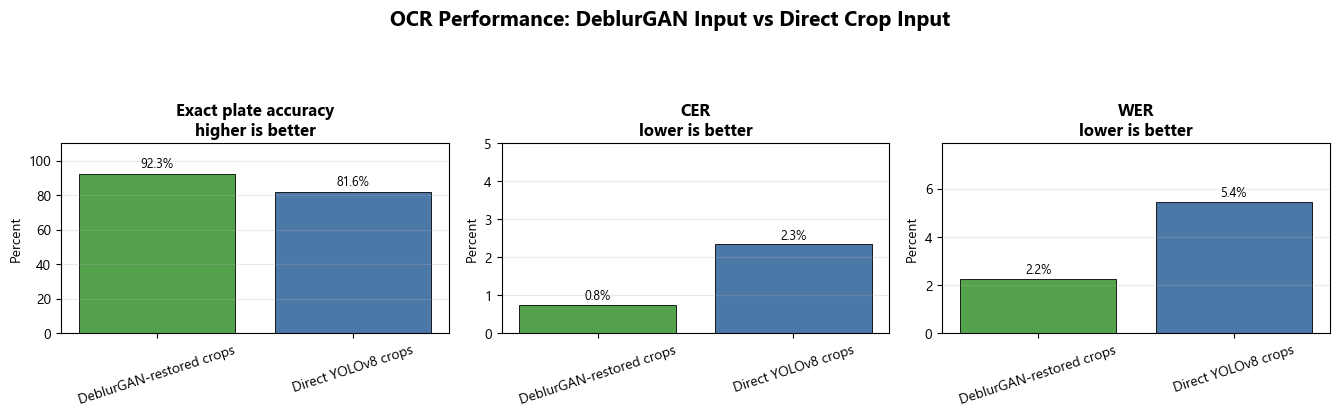

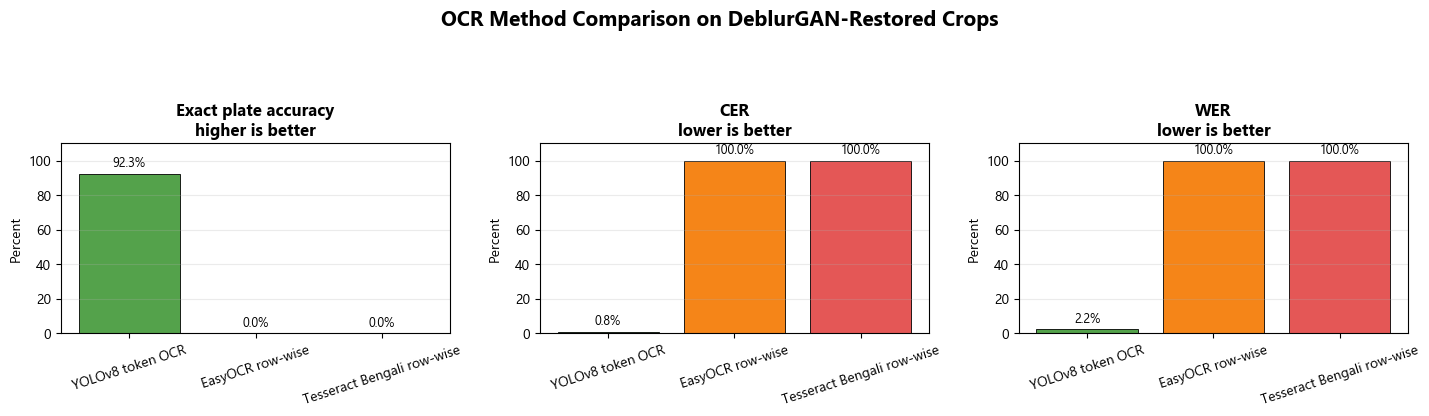

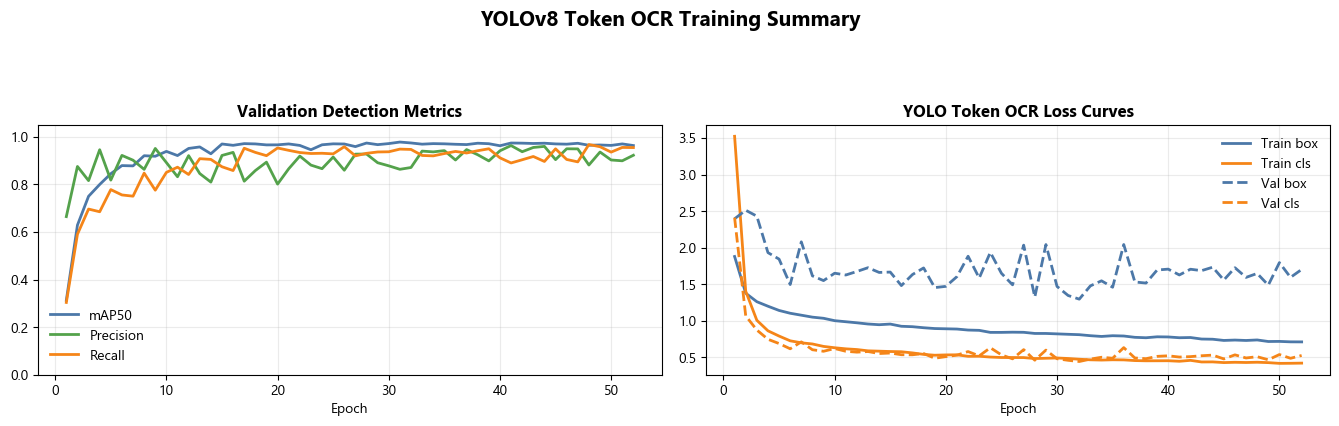

,ocr_input,samples,exact_plate_match_accuracy,cer,wer
0,DeblurGAN-restored crops,52,0.923077,0.007555,0.022436
1,Direct YOLOv8 crops,49,0.816327,0.023469,0.054422


,method,samples,cer,wer,exact_plate_match_accuracy
0,YOLOv8 token OCR,52,0.007555,0.022436,0.923077
1,EasyOCR row-wise,52,1.000000,1.000000,0.000000
2,Tesseract Bengali row-wise,52,1.000000,1.000000,0.000000


Saved OCR input comparison CSV: d:\thesis model training\runs\paper_pipeline_examples_final\ocr_presentation_graphs\ocr_input_branch_metric_comparison.csv
Saved OCR input comparison PNG: d:\thesis model training\runs\paper_pipeline_examples_final\ocr_presentation_graphs\ocr_input_branch_metric_comparison.png
Saved OCR input comparison PDF: d:\thesis model training\runs\paper_pipeline_examples_final\ocr_presentation_graphs\ocr_input_branch_metric_comparison.pdf
Saved OCR method comparison CSV: d:\thesis model training\runs\paper_pipeline_examples_final\ocr_presentation_graphs\ocr_method_metric_comparison.csv
Saved OCR method comparison PNG: d:\thesis model training\runs\paper_pipeline_examples_final\ocr_presentation_graphs\ocr_method_metric_comparison.png
Saved OCR method comparison PDF: d:\thesis model training\runs\paper_pipeline_examples_final\ocr_presentation_graphs\ocr_method_metric_comparison.pdf
Saved YOLO token training CSV: d:\thesis model training\runs\paper_pipeline_examples_

In [21]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(".").resolve()
FIGURE_OUTPUT_ROOT = Path(globals().get("OUTPUT_ROOT", PROJECT_ROOT / "runs" / "paper_pipeline_examples_final"))
OCR_PRESENTATION_ROOT = FIGURE_OUTPUT_ROOT / "ocr_presentation_graphs"
OCR_PRESENTATION_ROOT.mkdir(parents=True, exist_ok=True)

DEBLUR_OCR_SUMMARY_PATH = PROJECT_ROOT / "runs" / "ocr_text_recognition_psnr_v2" / "predictions" / "ocr_metric_summary.csv"
DIRECT_OCR_SUMMARY_PATH = PROJECT_ROOT / "runs" / "ocr_yolov8_input_token_ocr" / "predictions" / "ocr_metric_summary.csv"
YOLO_TOKEN_RESULTS_PATH = PROJECT_ROOT / "runs" / "ocr_text_recognition_psnr_v2" / "yolo_token_ocr" / "yolov8_token_detector" / "results.csv"

for required_path in [DEBLUR_OCR_SUMMARY_PATH, DIRECT_OCR_SUMMARY_PATH, YOLO_TOKEN_RESULTS_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(f"Missing OCR result file: {required_path}")


def percent(series):
    return series.astype(float) * 100.0


def label_bars(axis, bars, formatter="{:.1f}%"):
    max_height = max([bar.get_height() for bar in bars] + [1.0])
    for bar in bars:
        value = bar.get_height()
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            value + max_height * 0.025,
            formatter.format(value),
            ha="center",
            va="bottom",
            fontsize=9,
        )


def percent_axis_limit(values, force_hundred=False):
    max_value = float(np.nanmax(values))
    if force_hundred or max_value > 40.0:
        return 110.0
    return max(5.0, max_value * 1.45)


def yolo_token_row(frame):
    rows = frame[frame["method"].str.lower().eq("yolov8 token ocr")]
    if rows.empty:
        raise ValueError("Could not find YOLOv8 token OCR row in OCR summary.")
    return rows.iloc[0]


deblur_summary = pd.read_csv(DEBLUR_OCR_SUMMARY_PATH)
direct_summary = pd.read_csv(DIRECT_OCR_SUMMARY_PATH)

deblur_yolo = yolo_token_row(deblur_summary)
direct_yolo = yolo_token_row(direct_summary)

input_comparison_frame = pd.DataFrame([
    {
        "ocr_input": "DeblurGAN-restored crops",
        "samples": int(deblur_yolo["samples"]),
        "exact_plate_match_accuracy": float(deblur_yolo["exact_plate_match_accuracy"]),
        "cer": float(deblur_yolo["cer"]),
        "wer": float(deblur_yolo["wer"]),
    },
    {
        "ocr_input": "Direct YOLOv8 crops",
        "samples": int(direct_yolo["samples"]),
        "exact_plate_match_accuracy": float(direct_yolo["exact_plate_match_accuracy"]),
        "cer": float(direct_yolo["cer"]),
        "wer": float(direct_yolo["wer"]),
    },
])
input_comparison_csv = OCR_PRESENTATION_ROOT / "ocr_input_branch_metric_comparison.csv"
input_comparison_frame.to_csv(input_comparison_csv, index=False)

input_plot_frame = input_comparison_frame.copy()
for column in ["exact_plate_match_accuracy", "cer", "wer"]:
    input_plot_frame[column] = percent(input_plot_frame[column])

input_metric_specs = [
    ("Exact plate accuracy", "exact_plate_match_accuracy", "higher is better"),
    ("CER", "cer", "lower is better"),
    ("WER", "wer", "lower is better"),
]
input_colors = ["#54A24B", "#4C78A8"]

figure, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), facecolor="white")
for axis, (title, column, subtitle) in zip(axes, input_metric_specs):
    bars = axis.bar(input_plot_frame["ocr_input"], input_plot_frame[column], color=input_colors, edgecolor="black", linewidth=0.6)
    axis.set_title(f"{title}\n{subtitle}", fontsize=12, weight="bold")
    axis.set_ylabel("Percent")
    axis.grid(axis="y", alpha=0.25)
    axis.tick_params(axis="x", labelrotation=18)
    axis.set_ylim(0, percent_axis_limit(input_plot_frame[column], force_hundred=(column == "exact_plate_match_accuracy")))
    label_bars(axis, bars)

figure.suptitle("OCR Performance: DeblurGAN Input vs Direct Crop Input", fontsize=15, weight="bold")
figure.tight_layout(rect=[0, 0, 1, 0.88], w_pad=1.2)
input_png_path = OCR_PRESENTATION_ROOT / "ocr_input_branch_metric_comparison.png"
input_pdf_path = OCR_PRESENTATION_ROOT / "ocr_input_branch_metric_comparison.pdf"
figure.savefig(input_png_path, dpi=300, bbox_inches="tight")
figure.savefig(input_pdf_path, bbox_inches="tight")
plt.show()

method_comparison_frame = deblur_summary.copy()
method_comparison_csv = OCR_PRESENTATION_ROOT / "ocr_method_metric_comparison.csv"
method_comparison_frame.to_csv(method_comparison_csv, index=False)

method_plot_frame = method_comparison_frame.copy()
for column in ["exact_plate_match_accuracy", "cer", "wer"]:
    method_plot_frame[column] = percent(method_plot_frame[column])

method_colors = ["#54A24B", "#F58518", "#E45756"]
figure, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), facecolor="white")
for axis, (title, column, subtitle) in zip(axes, input_metric_specs):
    bars = axis.bar(method_plot_frame["method"], method_plot_frame[column], color=method_colors, edgecolor="black", linewidth=0.6)
    axis.set_title(f"{title}\n{subtitle}", fontsize=12, weight="bold")
    axis.set_ylabel("Percent")
    axis.grid(axis="y", alpha=0.25)
    axis.tick_params(axis="x", labelrotation=18)
    axis.set_ylim(0, percent_axis_limit(method_plot_frame[column], force_hundred=(column == "exact_plate_match_accuracy")))
    label_bars(axis, bars)

figure.suptitle("OCR Method Comparison on DeblurGAN-Restored Crops", fontsize=15, weight="bold")
figure.tight_layout(rect=[0, 0, 1, 0.88], w_pad=1.2)
method_png_path = OCR_PRESENTATION_ROOT / "ocr_method_metric_comparison.png"
method_pdf_path = OCR_PRESENTATION_ROOT / "ocr_method_metric_comparison.pdf"
figure.savefig(method_png_path, dpi=300, bbox_inches="tight")
figure.savefig(method_pdf_path, bbox_inches="tight")
plt.show()

training_frame = pd.read_csv(YOLO_TOKEN_RESULTS_PATH)
training_frame.columns = training_frame.columns.str.strip()
training_csv = OCR_PRESENTATION_ROOT / "ocr_yolo_token_training_curves.csv"
training_frame.to_csv(training_csv, index=False)

figure, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), facecolor="white")
axes[0].plot(training_frame["epoch"], training_frame["metrics/mAP50(B)"], label="mAP50", linewidth=2.0, color="#4C78A8")
axes[0].plot(training_frame["epoch"], training_frame["metrics/precision(B)"], label="Precision", linewidth=2.0, color="#54A24B")
axes[0].plot(training_frame["epoch"], training_frame["metrics/recall(B)"], label="Recall", linewidth=2.0, color="#F58518")
axes[0].set_title("Validation Detection Metrics", fontsize=12, weight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.25)
axes[0].legend(frameon=False)

axes[1].plot(training_frame["epoch"], training_frame["train/box_loss"], label="Train box", linewidth=2.0, color="#4C78A8")
axes[1].plot(training_frame["epoch"], training_frame["train/cls_loss"], label="Train cls", linewidth=2.0, color="#F58518")
axes[1].plot(training_frame["epoch"], training_frame["val/box_loss"], label="Val box", linewidth=2.0, linestyle="--", color="#4C78A8")
axes[1].plot(training_frame["epoch"], training_frame["val/cls_loss"], label="Val cls", linewidth=2.0, linestyle="--", color="#F58518")
axes[1].set_title("YOLO Token OCR Loss Curves", fontsize=12, weight="bold")
axes[1].set_xlabel("Epoch")
axes[1].grid(alpha=0.25)
axes[1].legend(frameon=False)

figure.suptitle("YOLOv8 Token OCR Training Summary", fontsize=15, weight="bold")
figure.tight_layout(rect=[0, 0, 1, 0.88], w_pad=1.2)
training_png_path = OCR_PRESENTATION_ROOT / "ocr_yolo_token_training_curves.png"
training_pdf_path = OCR_PRESENTATION_ROOT / "ocr_yolo_token_training_curves.pdf"
figure.savefig(training_png_path, dpi=300, bbox_inches="tight")
figure.savefig(training_pdf_path, bbox_inches="tight")
plt.show()

display(input_comparison_frame)
display(method_comparison_frame)
print("Saved OCR input comparison CSV:", input_comparison_csv)
print("Saved OCR input comparison PNG:", input_png_path)
print("Saved OCR input comparison PDF:", input_pdf_path)
print("Saved OCR method comparison CSV:", method_comparison_csv)
print("Saved OCR method comparison PNG:", method_png_path)
print("Saved OCR method comparison PDF:", method_pdf_path)
print("Saved YOLO token training CSV:", training_csv)
print("Saved YOLO token training PNG:", training_png_path)
print("Saved YOLO token training PDF:", training_pdf_path)